# Power maps of the MEA recordings

Computes the power (1-40 Hz) of each MEA channel and displays it as a heatmap overlaid on the picture of the slice.

Inputs: `info_recordings_astro1q.xlsx` (paths of the .h5 recordings) and the pictures `slice{n}.bmp` stored next to the recordings.

In [1]:
import pandas as pd
import numpy as np
from PIL import Image
from pathlib import Path

In [2]:
# Table of the recordings: path of the .h5 file, experiment ID, condition and slice number
info_path = Path('info_recordings_astro1q.xlsx')
info = pd.read_excel(info_path)
# Paths are relative to this folder; use '/' so that they also work on Linux/macOS
info['path'] = info['path'].str.replace('\\', '/')
display(info)

,path,ID,condition,slice
0,mea_rec\2025-01-27T16-29-37McsRecording.h5,AS-2025-000,baseline,10
1,mea_rec\2025-01-27T16-59-35McsRecording.h5,AS-2025-000,baseline,11
2,mea_rec\2025-01-27T17-41-23McsRecording.h5,AS-2025-000,baseline,12
3,mea_rec\2025-01-27T18-22-53McsRecording.h5,AS-2025-000,baseline,13
4,mea_rec\2025-01-27T18-50-57McsRecording.h5,AS-2025-000,baseline,14
5,mea_rec\2025-01-27T19-09-24McsRecording.h5,AS-2025-000,baseline,15
6,mea_rec\2025-01-27T19-30-19McsRecording.h5,AS-2025-000,baseline,16
7,mea_rec\2025-01-27T19-49-35McsRecording.h5,AS-2025-000,baseline,17


## Parameters: noisy channels and artefacted periods

In [3]:
# Noisy channels, excluded from the analysis
noise_channels =  ['A4', 'A5', 'B1', 'B2', 'B5', 'B6', 'B8', 'C2', 'C6', 'D3', 'D6', 'E6', 'F2', 'F4', 'F8', 'G10', 'L10', 'M9', 'E10']
# Artefacted periods to remove for each slice: list of (start, end) in seconds
bad_times = {'10' : [(4*60+36, 4*60+40)], '11' : [], '12' : [(1*60+6, 1*60+10)], 
             '13' : [(3*60+12, 3*60+14),(4*60+20, 4*60+24)], '14' : [], '15' : [],
               '16' : [], '17' : [(0,15), (7*60,7*60+3)]}

## Positioning of the electrodes on the slice pictures (interactive, run once)

In [4]:
%matplotlib qt
# Interactive positioning of the electrodes on the picture of each slice (needs a Qt backend).
# Positions are saved as .pkl files; slices already done are skipped.
from functions_mea import show_image_tag_channels

for i, row in info.iterrows() :
    show_image_tag_channels(row['ID'], row['slice'], Path(row['path']), folder = "position_channels")


AS-2025-000_10 already done
AS-2025-000_11 already done
AS-2025-000_12 already done
AS-2025-000_13 already done
AS-2025-000_14 already done
AS-2025-000_15 already done
AS-2025-000_16 already done
AS-2025-000_17 already done


## Power of each channel

In [55]:
from functions_mea import get_rec
import numpy as np
from spikeinterface.preprocessing import bandpass_filter

layout = 'sparse'  # MEA layout
dfs = 1000         # sampling frequency after resampling (Hz)
f1 = 1             # bandpass low cut-off (Hz)
f2 = 40            # bandpass high cut-off (Hz)

data = {'ID' : [], 'slice' : [], 'channel' : [], 'noisy' : [], 'power' : []}

for i, row in info.iterrows() :
    print(f'Processing {row["ID"]} slice {row["slice"]}')
    # Load the recording and bandpass filter it
    rec = get_rec(row['path'], dfs = dfs, layout = layout)
    traces = bandpass_filter(rec, freq_min=f1, freq_max=f2, dtype=np.float32)
    filtereds = traces.get_traces(return_scaled = True)
    # Set the artefacted periods to 0
    bad_times_slice = bad_times[str(row['slice'])]
    bad_frames = []
    for bt in bad_times_slice :
        bad_frames += list(range(bt[0]*dfs, bt[1]*dfs))
    filtereds[bad_frames,:] = 0
    # Power of each channel = mean of the squared filtered signal (µV²)
    channels = list(rec._properties['electrode_labels'])
    for c, channel in enumerate(channels) :
        data['ID'].append(row['ID'])
        data['slice'].append(row['slice'])
        data['channel'].append(channel)
        if channel in noise_channels :
            data['noisy'].append(True)
        else :
            data['noisy'].append(False)
        data['power'].append(np.mean(filtereds[:, c]**2))

# Save the power of all channels
data = pd.DataFrame(data)
data.to_csv('power_channels_astro1q.csv')

Processing AS-2025-000 slice 10
Processing AS-2025-000 slice 11
Processing AS-2025-000 slice 12
Processing AS-2025-000 slice 13
Processing AS-2025-000 slice 14
Processing AS-2025-000 slice 15
Processing AS-2025-000 slice 16
Processing AS-2025-000 slice 17


In [5]:
data = pd.read_csv('power_channels_astro1q.csv', index_col = 0)

## Power maps overlaid on the slices

In [6]:
import pickle
import matplotlib.pyplot as plt
import matplotlib.cm as clm

from functions_mea import channels_grid, channels_in, add_linear_transparency


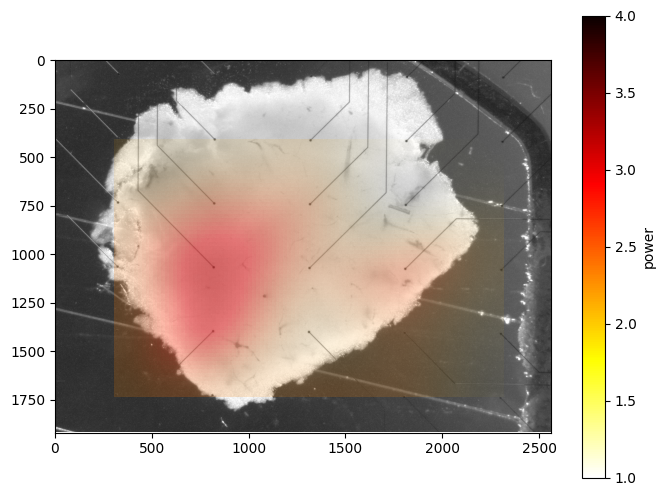

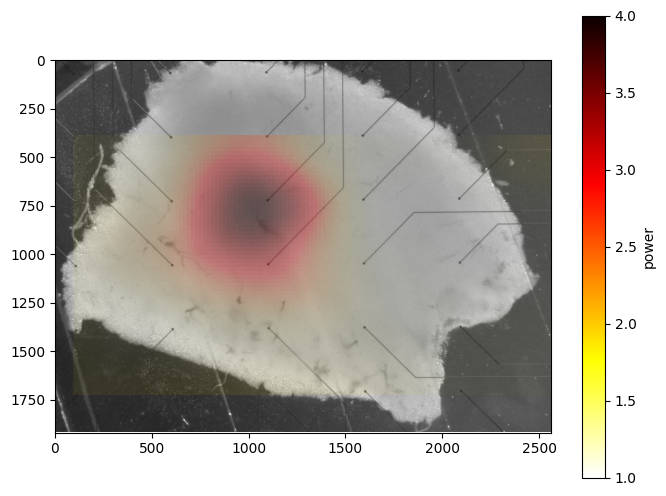

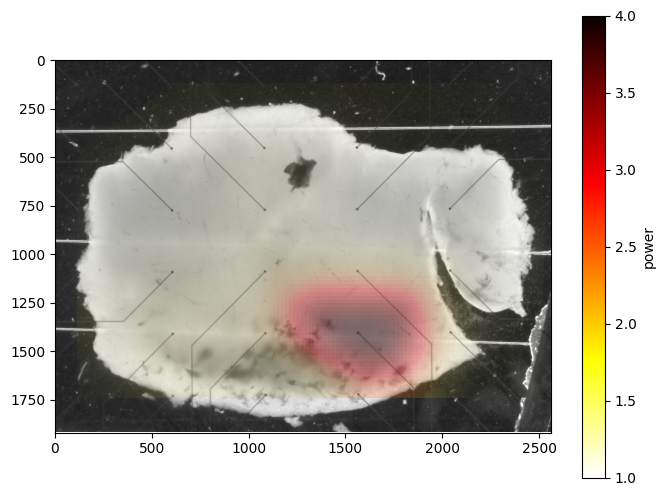

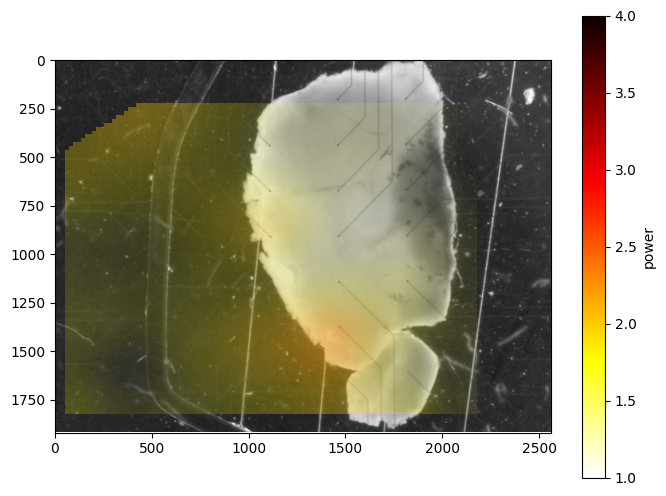

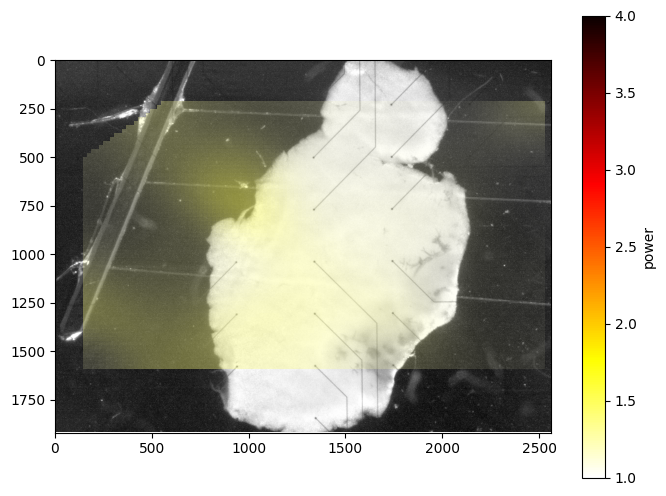

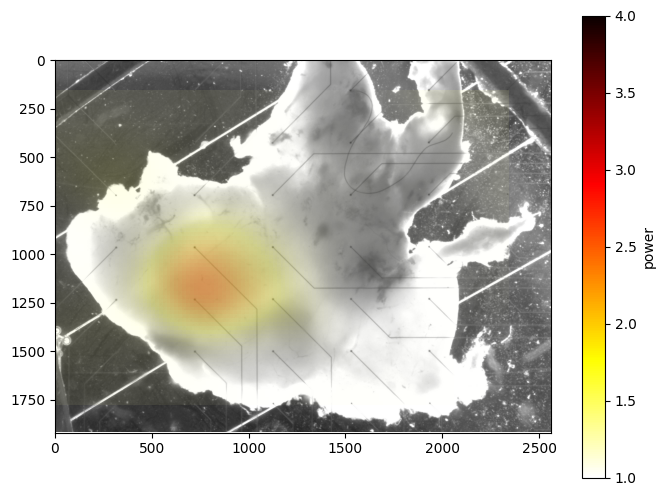

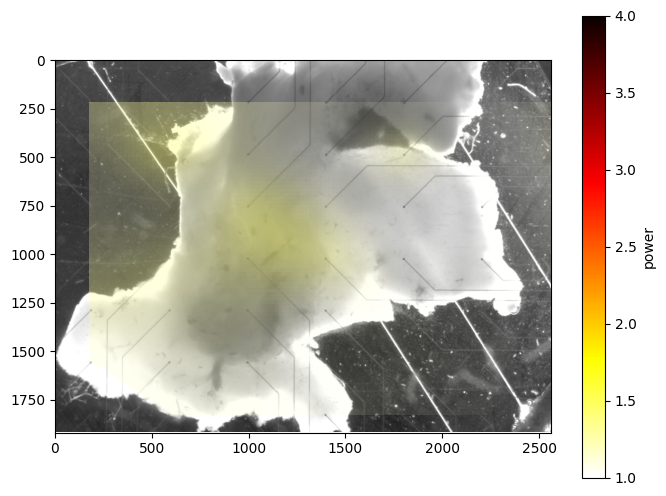

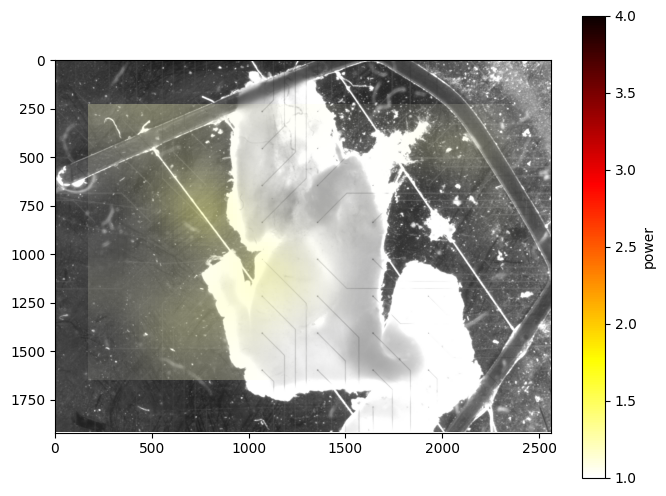

In [7]:
%matplotlib inline
mapcolor = 'hot_r'  # colormap of the power map
min_all = 1         # colormap limits (same for all slices)
max_all = 4
n_levels = 50       # number of levels of the contour map
feature = 'power'


for i, row in info.iterrows() :

    # Electrode positions on the picture (from show_image_tag_channels)
    pos_folder = Path('position_channels')
    positions_path = pos_folder / f'{row.ID}_{row.slice}.pkl'
    with open(positions_path, 'rb') as f:
        pos_pkl = pickle.load(f)

    pos_channels = pos_pkl['positions']
    min_max_channels= pos_pkl['min_max_channels']

    # Picture of the slice
    image_path = Path(row['path']).parent.absolute() / f'slice{row["slice"]}.bmp'
    img_use = Image.open(image_path)

    # All the electrodes located inside the slice (between the two extreme channels), with their x, y positions
    channels_do = channels_in(list(pos_channels.channel), min_max_channels[0], min_max_channels[1])
    pos_s = pos_channels[pos_channels.channel.isin(channels_do)]

    # Power of the non-noisy channels of this slice (noisy channels -> NaN)
    data_s = data[(data.ID == row.ID)&(data.slice == row.slice)&(data.noisy == False)]
    data_s = pos_s.merge(data_s[['channel', feature]], on='channel', how='left')

    # Grid of the MEA electrodes with their positions on the picture (2D X, Y: the grid can be rotated).
    # Noisy channels are filled by linear interpolation between the other channels.
    X, Y, Z = channels_grid(data_s, feature = feature)
    Z = np.clip(Z, min_all, max_all)

    # Colormap generated with contourf (marching squares, linear interpolation between channels),
    # overlaid on the picture with a transparency increasing with the power (alpha from 0 to 0.5)
    fig, ax = plt.subplots(figsize = (8,6))
    ax.imshow(img_use)
    levels = np.linspace(min_all, max_all, n_levels)
    cmap_alpha = add_linear_transparency(plt.get_cmap(mapcolor), max_alpha = 0.5)
    ax.contourf(X, Y, Z, levels = levels, cmap = cmap_alpha, vmin = min_all, vmax = max_all, antialiased = True)
    
    plt.colorbar(clm.ScalarMappable(norm=plt.Normalize(vmin=min_all, vmax=max_all), cmap=mapcolor), ax=ax, label = feature)

    ax.set_xlim(0, img_use.size[0]) 
    ax.set_ylim(img_use.size[1], 0)
    plt.show()
    

## Example traces

In [ ]:
from spikeinterface.preprocessing import bandpass_filter, highpass_filter
from matplotlib import patches

# Example traces of one channel: raw, bandpass filtered (IILDs) and highpass filtered (MUA)
s = 12          # slice
channel = 'G7'  # channel
row = info[(info.slice == s)].iloc[0]

# Plot limits (in samples) and y axis limits/ticks for each trace (µV)
xlim_long =  [30000,180000]
ylims = [[-150,80], [-150,80], [-25,15]]
yticks = [[-150,-50,50], [-150,-50,50], [-25,-15,-5,5]]

rec = get_rec(row['path'], dfs = dfs, layout = layout)
channels = list(rec._properties['electrode_labels'])
channel_ids = rec.channel_ids
channel_id = channel_ids[channels.index(channel)]

rec = rec.channel_slice([channel_id])

raw = rec.get_traces(return_scaled = True)
raw = np.array(raw).flatten()

filtered_IILDs = bandpass_filter(rec, freq_min=f1, freq_max=f2, dtype=np.float32).get_traces(return_scaled = True)
filtered_IILDs = np.array(filtered_IILDs).flatten()

filtered_MUA = highpass_filter(rec, freq_min=100, dtype=np.float32).get_traces(return_scaled = True)
filtered_MUA = np.array(filtered_MUA).flatten()


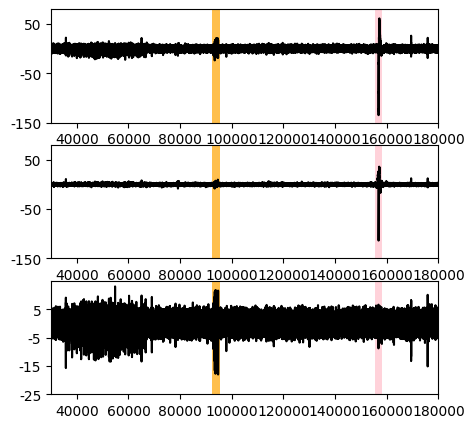

In [67]:
# Centers (in samples) of the two zoomed windows: MUA example and IILD example
peak_1 = 156798
MUA = 94000
window = 1500
xlims = [[MUA - window, MUA + window], [peak_1 - window, peak_1 + window]]

fc = ['orange', 'pink']

# Full traces with the zoomed windows highlighted
f,axes = plt.subplots(ncols = 1, nrows = 3, figsize = (5,5))

axes[0].plot(raw, c = 'black')
axes[1].plot(filtered_IILDs, c = 'black')
axes[2].plot(filtered_MUA, c = 'black')

for k, axe in enumerate(axes) : 
    axe.set_ylim(ylims[k])
    axe.set_xlim(xlim_long)
    axe.set_yticks(yticks[k], yticks[k])

    for xi, xlim in enumerate(xlims) :
        axe.add_patch(patches.Rectangle((xlim[0],ylims[k][0]), xlim[1]-xlim[0], ylims[k][1]-ylims[k][0], facecolor = fc[xi], alpha = 0.7))

plt.show()


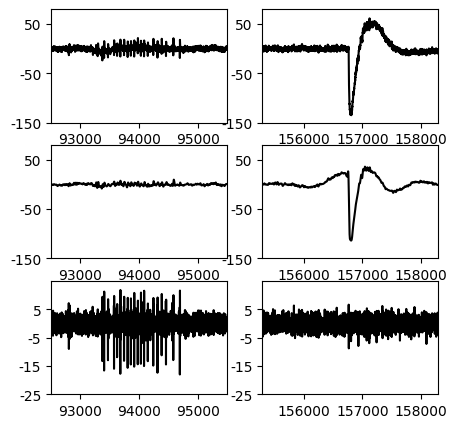

In [68]:
# Zoom on the two windows
f,axes = plt.subplots(ncols = 2, nrows = 3, figsize = (5,5))

for xi, xlim in enumerate(xlims) : 

    axes[0][xi].plot(raw, c = 'black')
    axes[1][xi].plot(filtered_IILDs, c = 'black')
    axes[2][xi].plot(filtered_MUA, c = 'black')

    for k, axe in enumerate(axes) : 
        axe[xi].set_ylim(ylims[k])
        axe[xi].set_xlim(xlim)
        axe[xi].set_yticks(yticks[k], yticks[k])


plt.show()
